# TabPFN v2: pinned pretrained tabular comparison

This evaluates a pretrained foundation model by conditioning on each outer training set. There is no task-specific gradient training, optimizer, or epoch selection. It does not train a large transformer from scratch.

**Use a separate Python 3.10–3.12 environment or fresh Colab runtime.** The pinned tabpfn 2.0.9 package requires scikit-learn below 1.7. Installing it in the original environment would downgrade scikit-learn. Follow `docs/deep_learning.md` to create a separate environment.

Package: tabpfn 2.0.9. Checkpoint: the official v2 classifier at a fixed Hugging Face revision, with an expected SHA256. The download is a separate cell you execute before reading participant data. Inference uses the local package, not a hosted prediction API.

Written but not executed or tested by the assistant. This is an implementation of the v2 model family, not a reproduction of every ensemble/configuration in the Nature benchmark.

## 1. Locate the project

The same private project directory and baseline artifacts are used. Only the Python environment is separate.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = None
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount('/content/drive')
    PROJECT_ROOT = PROJECT_ROOT or '/content/drive/MyDrive/ADNI_capstone'
ROOT = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/scripts/deep_models.py').is_file()), None)
if ROOT is None or not (ROOT / 'src/scripts/deep_models.py').is_file():
    raise FileNotFoundError('Set PROJECT_ROOT to the updated project folder.')
if not (3, 10) <= sys.version_info[:2] <= (3, 12):
    raise RuntimeError('Use Python 3.10–3.12 for this historical pinned environment.')
print('Python:', sys.executable)
print('Project:', ROOT)


Python: /opt/venv/python-stable/bin/python
Project: /Volumes/ColdCache/untitled folder/dddd/Tables_19Sep2026


## 2. Install only in the separate environment

Skip if already installed there. After installation, restart the kernel/runtime if requested and rerun the path cell. Do not install these pins into the original environment.

In [2]:
requirements_file = str(ROOT / 'requirements-tabpfn.txt')
%pip install -r "{requirements_file}"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 3.5 MB/s  0:00:03m 3.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 MB 2.8 MB/s  0:00:23 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 3.0 MB/s  0:00:023.1 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 2.8 MB/s  0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0━━━━━━━━━━━ 0/6 [sympy]
  Attempting uninstall: torch━━━━━━━━━━━━━━━━━━━━━━━━━ 0/6 [sympy]
    Found existing installation: torch 2.9.1━━━━━━ 0/6 [sympy]
    Uninstalling torch-2.9.1:━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/6 [torch]
      Successfully uninstalled torch-2.9.137m╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/6 [torch]
  Attempting uninstall: scikit-learn0m╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/6 [torch]
    Found existing installation: scikit-learn 1.7.2━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/6 [torch]
    U

## 3. Download the official checkpoint

This cell downloads about 29 MB of public weights. It does not read or upload participant records. Source: [official v2 checkpoint](https://huggingface.co/Prior-Labs/TabPFN-v2-clf/blob/main/tabpfn-v2-classifier.ckpt). The project's configuration pins the revision and SHA256; it never silently substitutes a newer model. See the model card and license for attribution.

An already downloaded matching file is reused. If authentication or access fails, use the official model page rather than substituting weights from an unrelated source.

In [6]:
   import os, certifi
   os.environ["SSL_CERT_FILE"] = certifi.where()
   os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

In [5]:
   %pip install --upgrade certifi

  Attempting uninstall: certifi
    Found existing installation: certifi 2025.11.12
    Uninstalling certifi-2025.11.12:
      Successfully uninstalled certifi-2025.11.12

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 3. Download the official checkpoint

This cell downloads about 29 MB of public weights. It does not read or upload participant records. Source: [official v2 checkpoint](https://huggingface.co/Prior-Labs/TabPFN-v2-clf/blob/main/tabpfn-v2-classifier.ckpt). The project's configuration pins the revision and SHA256; it never silently substitutes a newer model. See the model card and license for attribution.

An already downloaded matching file is reused. If authentication or access fails, use the official model page rather than substituting weights from an unrelated source.

In [7]:
import hashlib
import json
import urllib.request

cfg = json.loads((ROOT / 'config/deep_learning.json').read_text())
checkpoint = (ROOT / cfg['tabpfn']['model_path']).resolve()
if not checkpoint.is_relative_to(ROOT):
    raise ValueError('Checkpoint must remain inside the project.')
checkpoint.parent.mkdir(parents=True, exist_ok=True)
expected = cfg['tabpfn']['checkpoint_sha256']
if checkpoint.exists():
    if hashlib.sha256(checkpoint.read_bytes()).hexdigest() != expected:
        raise ValueError('Existing checkpoint has the wrong hash; inspect it before retrying.')
else:
    temporary = checkpoint.with_suffix('.download')
    urllib.request.urlretrieve(cfg['tabpfn']['checkpoint_url'], temporary)
    if hashlib.sha256(temporary.read_bytes()).hexdigest() != expected:
        raise ValueError('Downloaded checkpoint hash differs; do not load this file.')
    temporary.replace(checkpoint)
print('Pinned checkpoint ready:', checkpoint.name)


Pinned checkpoint ready: tabpfn-v2-classifier.ckpt


## 4. Fixed inference protocol

Use the same three experiments and five outer folds. Pass original numeric columns to TabPFN, explicitly identifying the sex/gender column as categorical. TabPFN handles its own training-data preprocessing; no global scaling or one-hot encoding is applied. The earlier complete-case eligibility is preserved.

Use four internal estimators and seeds 42/43/44. Report every seed and a separate seed-mean ensemble, with seed 42 prespecified as the primary single-seed result. Do not choose a seed based on outer scores. Each fit sees only outer training labels. The threshold is fixed at 0.5.

Logistic Regression is refitted in this environment to avoid comparing solely against numbers generated under a different scikit-learn version. No baseline joblib files are loaded. GPU is preferable; CPU is supported for these cohort sizes but may be slower.

In [8]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['TABPFN_DISABLE_TELEMETRY'] = '1'
import pandas as pd
from IPython.display import display, Image, Markdown
sys.path.insert(0, str(ROOT / 'src/scripts'))
from deep_models import load_data, run_deep_experiment
KIND = 'tabpfn'
REPORT = ROOT / 'reports/modeling' / cfg['run_name'] / KIND
manifest, cohorts = load_data(cfg)
display(pd.DataFrame([{'experiment': name, 'participants': len(frame), 'converters': int(frame.label.sum())} for name, frame in cohorts.items()]))
print(json.dumps(cfg['tabpfn'], indent=2))


,experiment,participants,converters
0,clinical_reference,589,216
1,matched_clinical,222,118
2,matched_fusion,222,118


{
  "package_version": "2.0.9",
  "model_path": "artifacts/pretrained/tabpfn-v2-classifier.ckpt",
  "checkpoint_url": "https://huggingface.co/Prior-Labs/TabPFN-v2-clf/resolve/758fe2b61e7665bb6fadd86fa6e0130a4a9b7dc4/tabpfn-v2-classifier.ckpt",
  "checkpoint_sha256": "f65a35685aeef42e31b796d9bfa34e68d6fc780bc98e7bff7763802964cf435f",
  "n_estimators": 4
}


## 5. Evaluate the pretrained model

Skip if this run is complete. This produces 45 fold/seed inference runs plus the Logistic Regression references. It does not fine-tune pretrained weights. Outputs are stored separately from MLP/ResNet and original results.

In [9]:
results = run_deep_experiment(cfg, KIND)


tabpfn: clinical_reference, outer fold 1/5, seed 42


/opt/venv/python-stable/lib/python3.10/site-packages/tabpfn/classifier.py:432: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  check_cpu_warning(


tabpfn: clinical_reference, outer fold 1/5, seed 43


/opt/venv/python-stable/lib/python3.10/site-packages/tabpfn/classifier.py:432: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  check_cpu_warning(


tabpfn: clinical_reference, outer fold 1/5, seed 44


...

tabpfn: clinical_reference, outer fold 5/5, seed 43


/opt/venv/python-stable/lib/python3.10/site-packages/tabpfn/classifier.py:432: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  check_cpu_warning(


tabpfn: clinical_reference, outer fold 5/5, seed 44


/opt/venv/python-stable/lib/python3.10/site-packages/tabpfn/classifier.py:432: UserWarning: Running on CPU with more than 200 samples may be slow.
Consider using a GPU or the tabpfn-client API: https://github.com/PriorLabs/tabpfn-client
  check_cpu_warning(


tabpfn: matched_clinical, outer fold 1/5, seed 42
tabpfn: matched_clinical, outer fold 1/5, seed 43
tabpfn: matched_clinical, outer fold 1/5, seed 44
tabpfn: matched_clinical, outer fold 2/5, seed 42
tabpfn: matched_clinical, outer fold 2/5, seed 43
tabpfn: matched_clinical, outer fold 2/5, seed 44
tabpfn: matched_clinical, outer fold 3/5, seed 42
tabpfn: matched_clinical, outer fold 3/5, seed 43
tabpfn: matched_clinical, outer fold 3/5, seed 44
tabpfn: matched_clinical, outer fold 4/5, seed 42
tabpfn: matched_clinical, outer fold 4/5, seed 43
tabpfn: matched_clinical, outer fold 4/5, seed 44
tabpfn: matched_clinical, outer fold 5/5, seed 42
tabpfn: matched_clinical, outer fold 5/5, seed 43
tabpfn: matched_clinical, outer fold 5/5, seed 44
tabpfn: matched_fusion, outer fold 1/5, seed 42
tabpfn: matched_fusion, outer fold 1/5, seed 43
tabpfn: matched_fusion, outer fold 1/5, seed 44
tabpfn: matched_fusion, outer fold 2/5, seed 42
tabpfn: matched_fusion, outer fold 2/5, seed 43
tabpfn: ma

## 6. Read results

Higher accuracy/AUROC/AP and lower Brier are better. Paired differences compare with same-run Logistic Regression. Seed variation is variation in this inference procedure, not independently sampled patient evidence.

,experiment,model,participants,accuracy,precision,sensitivity,specificity,f1,balanced_accuracy,auroc,average_precision,brier_score
0,clinical_reference,logistic_regression,589,84.4%,81.0%,75.0%,89.8%,77.9%,82.4%,0.912,0.852,0.110
1,clinical_reference,tabpfn_seed42,589,84.6%,79.9%,77.3%,88.7%,78.6%,83.0%,0.917,0.863,0.109
2,clinical_reference,tabpfn_seed43,589,84.9%,79.8%,78.7%,88.5%,79.3%,83.6%,0.916,0.863,0.109
3,clinical_reference,tabpfn_seed44,589,84.9%,80.1%,78.2%,88.7%,79.2%,83.5%,0.916,0.863,0.109
4,clinical_reference,tabpfn_seed_mean,589,84.7%,80.0%,77.8%,88.7%,78.9%,83.3%,0.917,0.863,0.109
5,matched_clinical,logistic_regression,222,80.6%,81.5%,82.2%,78.8%,81.9%,80.5%,0.898,0.917,0.130
6,matched_clinical,tabpfn_seed42,222,78.8%,79.8%,80.5%,76.9%,80.2%,78.7%,0.897,0.917,0.133
7,matched_clinical,tabpfn_seed43,222,78.8%,79.3%,81.4%,76.0%,80.3%,78.7%,0.896,0.915,0.133
8,matched_clinical,tabpfn_seed44,222,78.4%,79.2%,80.5%,76.0%,79.8%,78.2%,0.894,0.913,0.134
9,matched_clinical,tabpfn_seed_mean,222,78.8%,79.8%,80.5%,76.9%,80.2%,78.7%,0.895,0.915,0.133


,experiment,model,tn,fp,fn,tp
0,clinical_reference,logistic_regression,335,38,54,162
1,clinical_reference,tabpfn_seed42,331,42,49,167
2,clinical_reference,tabpfn_seed43,330,43,46,170
3,clinical_reference,tabpfn_seed44,331,42,47,169
4,clinical_reference,tabpfn_seed_mean,331,42,48,168
5,matched_clinical,logistic_regression,82,22,21,97
6,matched_clinical,tabpfn_seed42,80,24,23,95
7,matched_clinical,tabpfn_seed43,79,25,22,96
8,matched_clinical,tabpfn_seed44,79,25,23,95
9,matched_clinical,tabpfn_seed_mean,80,24,23,95


,experiment,metric,mean,std,min,max
0,clinical_reference,accuracy,0.8478,0.0020,0.8455,0.8489
1,clinical_reference,auroc,0.9165,0.0001,0.9164,0.9167
2,clinical_reference,average_precision,0.8628,0.0001,0.8628,0.8629
3,clinical_reference,brier_score,0.1094,0.0001,0.1093,0.1095
4,clinical_reference,sensitivity,0.7809,0.0071,0.7731,0.7870
5,clinical_reference,specificity,0.8865,0.0015,0.8847,0.8874
6,matched_clinical,accuracy,0.7868,0.0026,0.7838,0.7883
7,matched_clinical,auroc,0.8954,0.0015,0.8938,0.8968
8,matched_clinical,average_precision,0.9150,0.0021,0.9129,0.9171
9,matched_clinical,brier_score,0.1331,0.0005,0.1327,0.1337


,experiment,model,reference,metric,difference,lower_95,upper_95,bootstrap_samples
0,clinical_reference,tabpfn_seed42,logistic_regression,auroc,0.0046,-0.0044,0.0149,1000
1,clinical_reference,tabpfn_seed42,logistic_regression,average_precision,0.0109,-0.0102,0.0367,1000
2,clinical_reference,tabpfn_seed42,logistic_regression,brier_score,-0.0004,-0.0073,0.0060,1000
3,clinical_reference,tabpfn_seed42,logistic_regression,accuracy,0.0017,-0.0187,0.0221,1000
4,clinical_reference,tabpfn_seed_mean,logistic_regression,auroc,0.0047,-0.0043,0.0149,1000
5,clinical_reference,tabpfn_seed_mean,logistic_regression,average_precision,0.0109,-0.0109,0.0366,1000
6,clinical_reference,tabpfn_seed_mean,logistic_regression,brier_score,-0.0004,-0.0074,0.0060,1000
7,clinical_reference,tabpfn_seed_mean,logistic_regression,accuracy,0.0034,-0.0170,0.0238,1000
8,matched_clinical,tabpfn_seed42,logistic_regression,auroc,-0.0015,-0.0239,0.0190,1000
9,matched_clinical,tabpfn_seed42,logistic_regression,average_precision,-0.0001,-0.0185,0.0195,1000


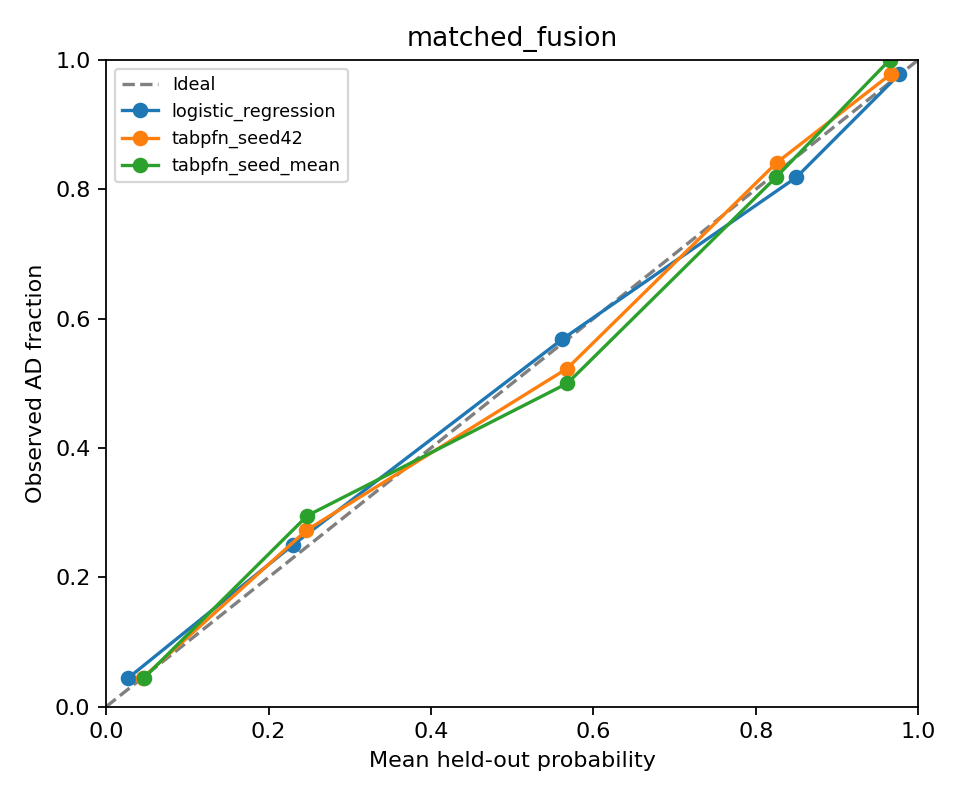

# Exploratory tabpfn results

| Experiment | Model | N | Accuracy | AUROC | AP | Brier |
|---|---|---:|---:|---:|---:|---:|
| clinical_reference | logistic_regression | 589 | 84.4% | 0.912 | 0.852 | 0.110 |
| clinical_reference | tabpfn_seed42 | 589 | 84.6% | 0.917 | 0.863 | 0.109 |
| clinical_reference | tabpfn_seed43 | 589 | 84.9% | 0.916 | 0.863 | 0.109 |
| clinical_reference | tabpfn_seed44 | 589 | 84.9% | 0.916 | 0.863 | 0.109 |
| clinical_reference | tabpfn_seed_mean | 589 | 84.7% | 0.917 | 0.863 | 0.109 |
| matched_clinical | logistic_regression | 222 | 80.6% | 0.898 | 0.917 | 0.130 |
| matched_clinical | tabpfn_seed42 | 222 | 78.8% | 0.897 | 0.917 | 0.133 |
| matched_clinical | tabpfn_seed43 | 222 | 78.8% | 0.896 | 0.915 | 0.133 |
| matched_clinical | tabpfn_seed44 | 222 | 78.4% | 0.894 | 0.913 | 0.134 |
| matched_clinical | tabpfn_seed_mean | 222 | 78.8% | 0.895 | 0.915 | 0.133 |
| matched_fusion | logistic_regression | 222 | 83.8% | 0.906 | 0.919 | 0.124 |
| matched_fusion | tabpfn_seed42 | 222 | 81.1% | 0.903 | 0.920 | 0.127 |
| matched_fusion | tabpfn_seed43 | 222 | 80.2% | 0.901 | 0.919 | 0.129 |
| matched_fusion | tabpfn_seed44 | 222 | 78.8% | 0.899 | 0.917 | 0.129 |
| matched_fusion | tabpfn_seed_mean | 222 | 79.7% | 0.901 | 0.919 | 0.128 |

## Interpretation

- The first configured seed (42) is the prespecified single-model result, not the best seed.
- The seed_mean row averages probabilities from all configured seeds. It is a separate seed ensemble, not the mean of the accuracy scores.
- Seed variability describes repeated fitting on the same participants. Seeds are not independent patient samples.
- The fixed Logistic Regression reference is refitted in the same environment on identical outer folds.
- Architecture, optimizer settings, and threshold were fixed. MLP/ResNet inner folds select training duration only; final models refit on the full outer training set.
- TabPFN uses a pinned pretrained model and no task-specific gradient optimization; this is not training a transformer from scratch.
- AP is non-interpolated average precision. Metric CSV rates use 0-1 scales; confusion counts are counts.
- Paired intervals condition on saved predictions, omit full retraining uncertainty, and are not adjusted for multiple comparisons.
- Previously inspected cohorts make this exploratory. Do not select the best result and call it independent confirmation.
- Broader clinical and matched cohorts are different populations. The matched cohort is ADNI1 only; labels remain provisional.
- Complete-case selection, unresolved outcomes, unavailable MRI/CSF comparisons, and no external validation remain limitations.


In [10]:
results = pd.read_csv(REPORT / 'metrics.csv')
columns = ['experiment', 'model', 'participants', 'accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy', 'auroc', 'average_precision', 'brier_score']
formats = {c: '{:.1%}' for c in ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'balanced_accuracy']}
formats.update({c: '{:.3f}' for c in ['auroc', 'average_precision', 'brier_score']})
display(results[columns].style.format(formats))
display(results[['experiment', 'model', 'tn', 'fp', 'fn', 'tp']])
display(pd.read_csv(REPORT / 'seed_variability.csv').round(4))
display(pd.read_csv(REPORT / 'paired_vs_logistic.csv').round(4))
display(Image(filename=str(REPORT / 'calibration_matched_fusion.png')))
display(Markdown((REPORT / 'results.md').read_text()))


## Interpretation and reproducibility

The private output retains cohort/fold snapshots, predictions, checkpoint hash, package versions, and per-fold/seed reconstruction recipes. It does not pickle 45 copies of a TabPFN inference engine. Recreate each fitted estimator using its recipe and saved outer training rows.

This is exploratory reuse of an already inspected cohort, not external validation. Conditional bootstrap intervals omit retraining uncertainty and are not adjusted for multiple comparisons. Complete-case selection and the ADNI1-only matched cohort remain limitations. The earlier SHAP figures do not explain this model.

Share metrics, paired comparisons, and seed variability with the MLP/ResNet results before deciding whether any added complexity is useful. No performance gain is assumed.